In [1]:
from models.feature_autoencoder import FeatureReconstructionModel
from utils.helpers import set_seed, get_device
from visualization import visualize_batch
from utils.data_split import split_data
from torchvision.transforms import v2
from dataset import MVTec2DDataset
import torch

W1105 10:02:02.368000 22824 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [2]:
config = {

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # model
    'base_channels': 16,
    'num_epochs': 50,
    'class_name': 'cable',  # Specify the class name for training and evaluation
}

In [3]:
set_seed(42)
DEVICE = get_device()


Random seed set to 42.
Using device: cuda.


In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

In [5]:
transforms = v2.Compose([
    v2.Resize(config['img_size']),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),  # valori in [0, 1]
])

target_transforms = v2.Compose([
    v2.Resize(config['img_size'], interpolation=v2.InterpolationMode.NEAREST),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

In [6]:
train_dataset = MVTec2DDataset(
    transforms=transforms,
    class_name=config['class_name'],
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    pin_memory=True,
)

val_dataset = MVTec2DDataset(
    transforms=transforms,
    split='validation',
    class_name=config['class_name']
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

test_dataset = MVTec2DDataset(
    transforms=transforms,
    target_transforms=target_transforms,
    split='test',
    class_name=config['class_name']
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

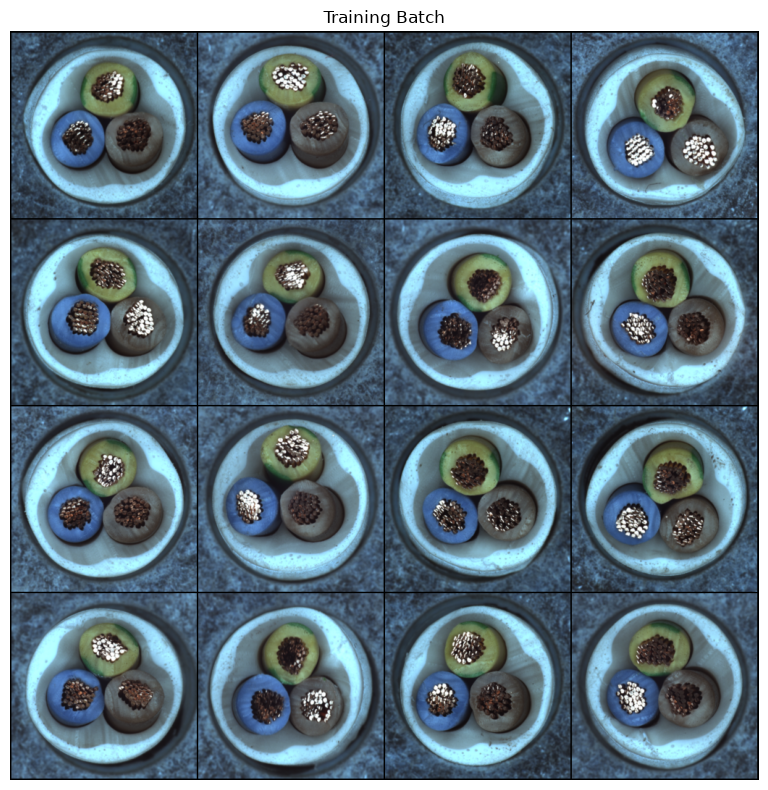

In [7]:
# visualize a batch of images
visualize_batch(train_loader)

In [8]:
# instantiate the model
model = FeatureReconstructionModel(backbone_name='resnet18', feature_layers=['layer2']).to(DEVICE)

In [ ]:
# make a single forward pass to check if the model works
# sample_batch = next(iter(train_loader))
# model.train()  # Set the model to training mode
# with torch.no_grad():
#     res = model(sample_batch['image'].to(DEVICE))
#     print(f"Model output: {res}")

Target feature shape: torch.Size([16, 128, 32, 32]), Reconstructed feature shape: torch.Size([16, 128, 32, 32])
Model output: (tensor([[[[4.6632e-01, 0.0000e+00, 3.6574e-01,  ..., 0.0000e+00,
           2.1322e-01, 4.7910e-01],
          [5.0659e-01, 1.6315e-01, 1.6552e-02,  ..., 0.0000e+00,
           0.0000e+00, 5.3426e-01],
          [4.4869e-01, 0.0000e+00, 4.1506e-02,  ..., 3.4847e-01,
           0.0000e+00, 0.0000e+00],
          ...,
          [0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00,
           0.0000e+00, 1.5997e-01],
          [2.3389e-01, 1.4596e-01, 0.0000e+00,  ..., 0.0000e+00,
           6.4563e-01, 1.9175e-01],
          [5.3320e-01, 6.3822e-01, 9.4437e-02,  ..., 6.6755e-01,
           9.0272e-01, 4.9005e-01]],

         [[0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 2.9537e-01,
           1.3990e-01, 1.8101e-01],
          [1.3246e-01, 0.0000e+00, 0.0000e+00,  ..., 5.6330e-02,
           0.0000e+00, 4.0555e-01],
          [3.6819e-01, 0.0000e+00, 2.4432e-02,  